<a href="https://colab.research.google.com/github/DEESHA-AFK/MACHINE-LEARNING-FUNDAMENTALS/blob/main/T076_ML_PRAC_2_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AIM: KNN for breast cancer medical diagnosis
Use KNN on Wisconsin Breast Cancer dataset to classify tumors as
benign/malignant (real-world oncology decision support). Compare accuracy with
different distance metrics.

Load Dataset & Before KNN Graph

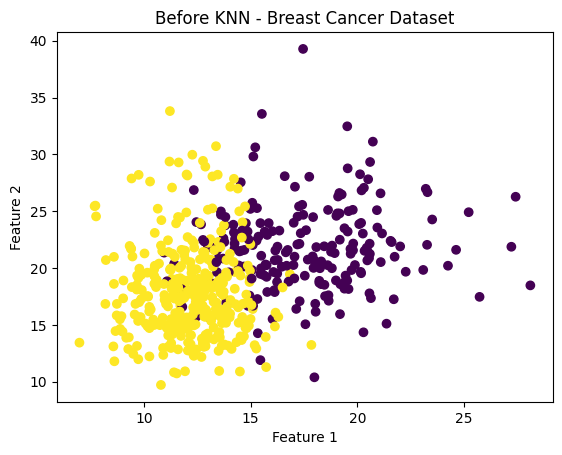

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Before KNN - Breast Cancer Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Apply KNN with Different Distance Metrics

In [2]:
metrics = ['euclidean', 'manhattan', 'minkowski']
accuracies = []

for metric in metrics:
    model = KNeighborsClassifier(n_neighbors=5, metric=metric)
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred) * 100

    accuracies.append(acc)
    print(metric, "Accuracy:", round(acc, 2), "%")

euclidean Accuracy: 95.61 %
manhattan Accuracy: 96.49 %
minkowski Accuracy: 95.61 %


After KNN Graph & Accuracy Comparison

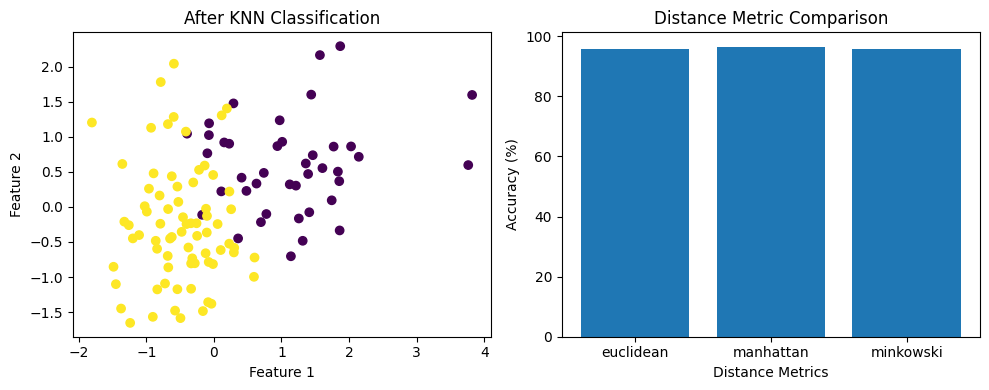

In [3]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.scatter(X_test[:, 0], X_test[:, 1], c=pred)
plt.title("After KNN Classification")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1,2,2)
plt.bar(metrics, accuracies)
plt.title("Distance Metric Comparison")
plt.xlabel("Distance Metrics")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.show()